# Vẽ lại quá trình train Hybrid: KB3–TPE → KB2–DPO

Notebook đọc **log đã lưu**, không train lại, không nạp weights và không chạy model inference.
Chọn **Run All** để tạo biểu đồ, xuất PNG/PDF/SVG và bảng CSV.

- **Giai đoạn 1:** search 8 trial HPO; từng trial train độc lập từ pretrained. Winner là trial 2,
  native-selected epoch 139 trong 169 epoch thực chạy.
- **Giai đoạn 2:** KB2 tiếp tục từ checkpoint TPE, λ=0,03, β=0,1, background=0,5.
  Run đủ 15.000 optimizer update; checkpoint được chọn ở update 500.
- **Đọc trục đúng:** HPO theo **epoch**, KB2 theo **optimizer update**.
- **Đọc evaluator đúng:** đường mỗi epoch của HPO là **native validation**. Score TPE giữa các
  trial và đường validation KB2 là **canonical**. Vì vậy không nối chúng thành một đường mAP liên tục.
  Ví dụ winner epoch139 có native mAP 42,373%, nhưng canonical checkpoint score lịch sử là38,5071%.

Phụ thuộc: `numpy`, `pandas`, `matplotlib` trong Python kernel đang chọn. Không có cell tự cài thư viện.
Nếu VS Code chưa có Python kernel, cài/chọn môi trường Jupyter phù hợp trước khi Run All.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string(index=False) if isinstance(value, pd.DataFrame) else value)

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 12, "axes.labelsize": 10,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.18,
    "savefig.facecolor": "white", "pdf.fonttype": 42, "ps.fonttype": 42,
})
COLORS = {"hpo": "#2463A6", "dpo": "#237A57", "anchor": "#7B8490",
          "tradeoff": "#B76532", "purple": "#8660A8", "ink": "#3F3428"}
pd.set_option("display.max_columns", 18)
pd.set_option("display.width", 160)


## 1. Cấu hình đường dẫn và cách xuất hình

Mặc định notebook tự tìm repo từ thư mục đang mở, chạy được từ root hoặc `notebooks/`.
Nếu mở notebook ở nơi khác, điền `REPO_ROOT_HINT` bằng đường dẫn repo của bạn.
Đổi `TRIALS_TO_PLOT` để chỉ xem một số trial; đổi `FOCUS_TRIAL` để xem chi tiết trial khác.
Mặc định focus đúng winner được ghi trong `evaluation.json`.

`SMOOTH_WINDOW` tính theo **số bản ghi train được log**, không phải số update.
Đường validation giữ nguyên các điểm đo, không smoothing.


In [2]:
REPO_ROOT_HINT = None                 # Ví dụ: Path("/path/to/RL-YOLO")
TRIALS_TO_PLOT = None                  # None = cả 8 trial; hoặc [0, 2]
FOCUS_TRIAL = None                     # None = winner trong evaluation.json
SMOOTH_WINDOW = 15                     # Rolling mean trailing, chỉ dùng cho train loss
SAVE_FIGURES = True
SAVE_FORMATS = ("png", "pdf", "svg")
FIGURE_DPI = 220

def find_repo_root(hint=None):
    if hint is not None:
        candidates = [Path(hint).expanduser().resolve()]
    else:
        current = Path.cwd().resolve()
        candidates = [current, *current.parents]
    for candidate in candidates:
        if (candidate / "kb3_hyperparameter_optimization").is_dir() and (candidate / "kb2_preference_optimization").is_dir():
            return candidate
    raise FileNotFoundError("Không tìm thấy root RL-YOLO. Hãy điền REPO_ROOT_HINT ở cell này.")

REPO_ROOT = find_repo_root(REPO_ROOT_HINT)
KB3_RUN = REPO_ROOT / "kb3_hyperparameter_optimization/checkpoint_hyperparameter_optimization/quality/tpe_kb1_pretrained_v2/yolov8n"
KB2_RUN = REPO_ROOT / "kb2_preference_optimization/outputs/yolov8n_hybrid_schedule_s42_20261106_trial3/run/dpo"
SELECTED_RECORD = REPO_ROOT / "docs/report_final/assets/kb2_hybrid_selected_20261108/selection.json"
FINAL_METRICS_CSV = REPO_ROOT / "docs/report_final/assets/kb2_hybrid_selected_20261108/metrics.csv"
OUTPUT_DIR = REPO_ROOT / "docs/report_final/assets/hybrid_training_curves_20261113"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert isinstance(SMOOTH_WINDOW, int) and SMOOTH_WINDOW >= 1
print("Repo:", REPO_ROOT)
print("KB3:", KB3_RUN.relative_to(REPO_ROOT))
print("KB2:", KB2_RUN.relative_to(REPO_ROOT))
print("Xuất hình và CSV:", OUTPUT_DIR.relative_to(REPO_ROOT))


Repo: /home/celine/Celine/graduate/RL-YOLO
KB3: kb3_hyperparameter_optimization/checkpoint_hyperparameter_optimization/quality/tpe_kb1_pretrained_v2/yolov8n
KB2: kb2_preference_optimization/outputs/yolov8n_hybrid_schedule_s42_20261106_trial3/run/dpo
Xuất hình và CSV: docs/report_final/assets/hybrid_training_curves_20261113


## 2. Đọc log và kiểm tra đúng lượt Hybrid

Nguồn HPO: `evaluation.json`, `tpe/trial_XXXX/epochs.json`, `result.json`, `trial_spec.json`,
`native/results.csv`. Đường Windows trong metadata lịch sử không được dùng để tìm log;
notebook tìm theo trial ID trong workspace hiện tại.

Nguồn KB2: `manifest.json`, `selection.json`, `completed.json`, `metrics.jsonl`.
Notebook kiểm nguồn KB2 khớp checkpoint hash winner TPE, số epoch/update, selected step và giá trị metric.


In [3]:
INPUT_FILES = []

def read_json(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Thiếu log: {path}. Notebook cần log gốc; CSV tổng hợp không đủ để vẽ loss theo thời gian.")
    INPUT_FILES.append(path)
    return json.loads(path.read_text(encoding="utf-8-sig"))

evaluation = read_json(KB3_RUN / "evaluation.json")
assert evaluation["method"] == "A-TPE" and evaluation["metrics_split"] == "validation"
WINNER_TRIAL = int(evaluation["best_trial"])
FOCUS_TRIAL = WINNER_TRIAL if FOCUS_TRIAL is None else int(FOCUS_TRIAL)
trial_ids = sorted(int(row["trial"]) for row in evaluation["trials"])
assert len(trial_ids) == evaluation["completed_trials"] == evaluation["requested_trials"]
if TRIALS_TO_PLOT is None:
    TRIALS_TO_PLOT = trial_ids.copy()
else:
    TRIALS_TO_PLOT = list(dict.fromkeys(int(t) for t in TRIALS_TO_PLOT))
if not TRIALS_TO_PLOT or not set(TRIALS_TO_PLOT).issubset(trial_ids) or FOCUS_TRIAL not in trial_ids:
    raise ValueError(f"Trial hợp lệ: {trial_ids}; kiểm tra TRIALS_TO_PLOT và FOCUS_TRIAL.")

epoch_frames, component_frames, trial_rows = [], {}, []
trial_results = {}
for trial in trial_ids:
    folder = KB3_RUN / "tpe" / f"trial_{trial:04d}"
    history = read_json(folder / "epochs.json")
    result = read_json(folder / "result.json")
    proposal = read_json(folder / "trial_spec.json")
    assert not result["failed"] and result["initialization"] == "pretrained"
    assert len(proposal["history_objectives"]) == trial
    assert {row["metrics_protocol"] for row in history} == {"ultralytics_native_validation"}
    records = []
    for row in history:
        record = {"trial": trial, **row["metrics"], "native_fitness": row["native_fitness"]}
        record.update({f"lr_pg{i}": value for i, value in enumerate(row["optimizer_lr"])})
        records.append(record)
    frame = pd.DataFrame(records).sort_values("epoch").reset_index(drop=True)
    assert frame["epoch"].tolist() == list(range(1, result["actual_epochs"] + 1))
    epoch_frames.append(frame)
    trial_results[trial] = result
    best_epoch = int(result["metrics"]["epoch"])
    scores = result["canonical_best_scores"]
    trial_rows.append({
        "trial": trial, "mode": proposal["mode"],
        "lr0": result["hyperparameters"]["lr0"],
        "weight_decay": result["hyperparameters"]["weight_decay"],
        "best_epoch": best_epoch, "actual_epochs": int(result["actual_epochs"]),
        "native_mAP_at_best": float(frame.set_index("epoch").loc[best_epoch, "map50_95"]),
        "canonical_mAP50_95": float(scores["mAP50_95"]),
        "canonical_mAP50": float(scores["mAP50"]),
        "operating_precision": float(scores["precision"]),
        "operating_recall": float(scores["operating_recall"]),
        "operating_f1": float(scores["f1"]),
        "hours_result": float(result["elapsed_seconds"]) / 3600,
    })
    csv_path = folder / "native/results.csv"
    if csv_path.exists():
        INPUT_FILES.append(csv_path)
        component = pd.read_csv(csv_path)
        component.columns = component.columns.str.strip()
        component = component.apply(pd.to_numeric, errors="raise")
        assert component["epoch"].astype(int).tolist() == frame["epoch"].tolist()
        component_frames[trial] = component

hpo_epochs = pd.concat(epoch_frames, ignore_index=True)
hpo_trials = pd.DataFrame(trial_rows).sort_values("trial").reset_index(drop=True)
assert int(hpo_trials.loc[hpo_trials["canonical_mAP50_95"].idxmax(), "trial"]) == WINNER_TRIAL
assert hpo_trials["actual_epochs"].sum() == evaluation["actual_epochs"]

kb2_manifest = read_json(KB2_RUN / "manifest.json")
kb2_selection = read_json(KB2_RUN / "selection.json")
kb2_completed = read_json(KB2_RUN / "completed.json")
selected_record = read_json(SELECTED_RECORD)
cfg = kb2_manifest["config"]
source_tpe = kb2_manifest["provenance"]["source_tpe"]
assert int(source_tpe["trial"]) == WINNER_TRIAL
assert source_tpe["checkpoint_sha256"] == evaluation["best_checkpoint_sha256"]
DPO_WEIGHT = float(cfg["dpo_weight"])
BETA = float(cfg["beta"])
LR_DROP_STEP = int(cfg["lr_schedule"]["drop_after_update"])
BUDGET = int(cfg["steps"])
SELECTED_STEP = int(kb2_selection["best_AP_step"])
assert SELECTED_STEP == int(kb2_completed["best_step"]) == int(selected_record["selected_update"])
assert np.isclose(DPO_WEIGHT, selected_record["lambda"]) and np.isclose(BETA, selected_record["beta"])

log_path = KB2_RUN / "metrics.jsonl"
if not log_path.is_file():
    raise FileNotFoundError(f"Thiếu train/validation log: {log_path}")
INPUT_FILES.append(log_path)
events = []
with log_path.open(encoding="utf-8") as handle:
    for line_no, line in enumerate(handle, 1):
        if line.strip():
            try:
                events.append(json.loads(line))
            except json.JSONDecodeError as error:
                raise ValueError(f"JSON lỗi tại {log_path.name}, dòng {line_no}") from error

train_events = [row for row in events if row["event"] == "train"]
validation_events = [row for row in events if row["event"] == "validation"]
if not train_events or not validation_events:
    raise ValueError("Log không có đủ train events và validation events.")
kb2_train = pd.json_normalize(train_events).drop(columns=["event"]).sort_values("step").reset_index(drop=True)
metric_names = ["mAP50_95", "mAP50", "mAP75", "precision", "operating_recall", "f1",
                "macro_f1", "macro_recall", "AR300", "APs", "APm", "APl", "tp", "fp", "fn"]
kb2_validation = pd.DataFrame([
    {"step": row["step"], "selected_best_at_time": row.get("selected_best", False),
     **{key: row["metrics"].get(key, np.nan) for key in metric_names}}
    for row in validation_events
]).sort_values("step").reset_index(drop=True)
for frame in (kb2_train, kb2_validation):
    assert not frame["step"].duplicated().any(), "Trùng step trong log; kiểm tra nguồn run."
assert kb2_train["step"].iloc[-1] == BUDGET == kb2_validation["step"].iloc[-1]
assert kb2_validation["step"].iloc[0] == 0
assert kb2_validation["step"].tolist() == cfg["evaluation_steps"]
selected_row = kb2_validation.set_index("step").loc[SELECTED_STEP]
assert np.isclose(selected_row["mAP50_95"], kb2_selection["best_AP_score"], atol=1e-10, rtol=0)
assert np.isclose(selected_row["mAP50_95"], selected_record["metrics"]["mAP50_95"], atol=1e-10, rtol=0)
assert int(kb2_validation.loc[kb2_validation["mAP50_95"].idxmax(), "step"]) == SELECTED_STEP
kb2_train["weighted_dpo_loss"] = DPO_WEIGHT * kb2_train["dpo_loss"]
kb2_train["total_loss_reconstructed"] = kb2_train["native_loss"] + kb2_train["weighted_dpo_loss"]
assert np.isfinite(hpo_epochs[["train_loss", "val_loss", "map50_95"]].to_numpy()).all()
assert np.isfinite(kb2_train[["native_loss", "dpo_loss", "total_loss_reconstructed"]].to_numpy()).all()
assert np.isfinite(kb2_validation[metric_names].to_numpy()).all()

FOCUS = hpo_epochs.loc[hpo_epochs["trial"] == FOCUS_TRIAL].copy()
FOCUS_BEST_EPOCH = int(trial_results[FOCUS_TRIAL]["metrics"]["epoch"])
WINNER_BEST_EPOCH = int(trial_results[WINNER_TRIAL]["metrics"]["epoch"])
print(f"HPO: {len(trial_ids)} trial, {len(hpo_epochs):,} epoch được log; winner trial {WINNER_TRIAL}, best epoch {WINNER_BEST_EPOCH}.")
print(f"KB2: {len(kb2_train):,} train records, {len(kb2_validation)} validation records; budget {BUDGET:,}, selected step {SELECTED_STEP}.")
print(f"λ={DPO_WEIGHT}; β={BETA}; background={cfg['native_background_weight']}; selected mAP={100*selected_row['mAP50_95']:.4f}%.")
display(hpo_trials.round(6))


HPO: 8 trial, 1,387 epoch được log; winner trial 2, best epoch 139.
KB2: 601 train records, 22 validation records; budget 15,000, selected step 500.
λ=0.03; β=0.1; background=0.5; selected mAP=38.7133%.
 trial           mode      lr0  weight_decay  best_epoch  actual_epochs  native_mAP_at_best  canonical_mAP50_95  canonical_mAP50  operating_precision  operating_recall  operating_f1  hours_result
     0     kb1_anchor 0.010000      0.000500          91            121             0.39584            0.360677         0.477005             0.490785          0.493906      0.492340      1.925813
     1 startup_random 0.005674      0.000582         149            179             0.42153            0.377225         0.494553             0.495915          0.546900      0.520161      2.753655
     2            tpe 0.005355      0.000913         139            169             0.42373            0.385071         0.504298             0.508763          0.553789      0.530322      2.611561
     3       

## 3. Hàm vẽ và xuất hình

Các hình loss hiển thị cả bản ghi gốc (mờ) và rolling mean (đậm).
Vertical marker chỉ mốc **được chọn theo selector**, không mặc định là minimum của mọi loss.
Các đường nối validation chỉ nối những mốc đã evaluate, không tạo thêm metric ở giữa.


In [4]:
FIGURE_FILES = []

def finish_figure(fig, stem, note=None):
    if note:
        fig.text(0.5, 0.012, note, ha="center", va="bottom", fontsize=8, color="#665F55")
    fig.tight_layout(rect=(0, 0.055 if note else 0, 1, 0.94))
    if SAVE_FIGURES:
        for extension in SAVE_FORMATS:
            destination = OUTPUT_DIR / f"{stem}.{extension}"
            fig.savefig(destination, dpi=FIGURE_DPI, bbox_inches="tight")
            FIGURE_FILES.append(destination)
    plt.show()
    plt.close(fig)

def loss_trace(ax, frame, column, color, label):
    ax.plot(frame["step"], frame[column], lw=0.8, alpha=0.20, color=color, label=f"{label} — raw")
    smoothed = frame[column].rolling(SMOOTH_WINDOW, min_periods=1).mean()
    ax.plot(frame["step"], smoothed, lw=1.8, color=color, label=f"{label} — rolling {SMOOTH_WINDOW} records")
    ax.set_xlabel("Optimizer update")
    ax.set_ylabel("Loss")

def mark_kb2(ax, *, add_labels=True):
    ax.axvline(SELECTED_STEP, color=COLORS["dpo"], ls="--", lw=1.2,
               label=f"Selected update {SELECTED_STEP}" if add_labels else None)
    if LR_DROP_STEP > 0:
        ax.axvline(LR_DROP_STEP, color=COLORS["tradeoff"], ls=":", lw=1.2,
                   label=f"LR giảm SAU {LR_DROP_STEP}" if add_labels else None)

def percent_axis(ax):
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:g}%"))

def trial_color(trial):
    if trial == WINNER_TRIAL:
        return COLORS["hpo"]
    if trial == 0:
        return COLORS["anchor"]
    return plt.get_cmap("tab10")(trial % 10)


## 4. HPO: quá trình search giữa các trial

Mỗi điểm bên trái là **canonical mAP của native-selected checkpoint**, cũng là objective lịch sử
TPE thực sự nhận. Đường best-so-far minh họa incumbent trong các cấu hình đã thử.
Hình bên phải biểu diễn vị trí LR/WD đã thử; không phải density nội bộ của TPE.

Trial0 anchor và trial1 startup random; từ trial2 là proposal TPE. Mỗi trial train lại từ pretrained,
không nối weights của trial trước. Score lịch sử giữ nguyên, khác rất nhỏ so với lần reload bảng cuối.


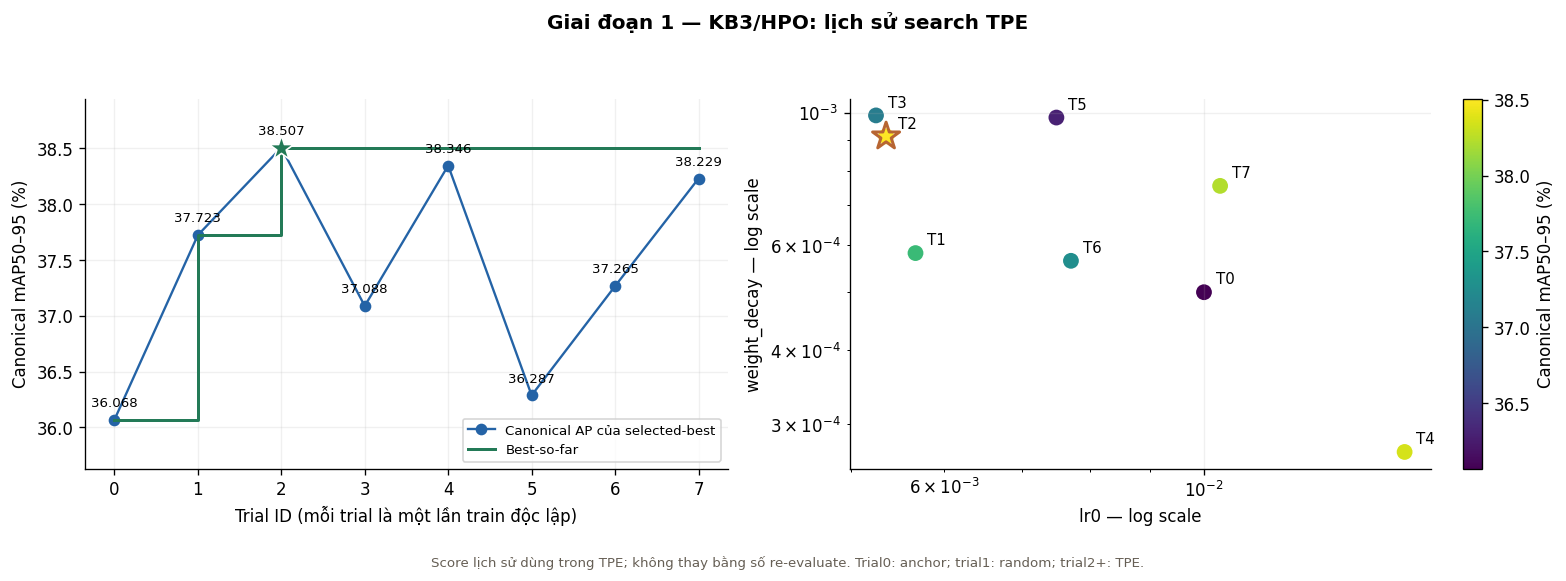

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8))
fig.suptitle("Giai đoạn 1 — KB3/HPO: lịch sử search TPE", fontweight="bold")
xs = hpo_trials["trial"].to_numpy()
ys = 100 * hpo_trials["canonical_mAP50_95"].to_numpy()
axes[0].plot(xs, ys, "o-", color=COLORS["hpo"], lw=1.4, label="Canonical AP của selected-best")
axes[0].step(xs, np.maximum.accumulate(ys), where="post", color=COLORS["dpo"], lw=1.8, label="Best-so-far")
for trial, score in zip(xs, ys):
    axes[0].annotate(f"{score:.3f}", (trial, score), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
winner_y = float(hpo_trials.set_index("trial").loc[WINNER_TRIAL, "canonical_mAP50_95"]) * 100
axes[0].scatter([WINNER_TRIAL], [winner_y], marker="*", s=240, color=COLORS["dpo"], edgecolors="white", zorder=5)
axes[0].set(xlabel="Trial ID (mỗi trial là một lần train độc lập)", ylabel="Canonical mAP50–95 (%)")
axes[0].set_xticks(xs)
axes[0].margins(y=0.18)
axes[0].legend(fontsize=8, loc="lower right")
scatter = axes[1].scatter(hpo_trials["lr0"], hpo_trials["weight_decay"], c=ys, s=110, cmap="viridis", edgecolors="white")
for row in hpo_trials.itertuples():
    axes[1].annotate(f"T{row.trial}", (row.lr0, row.weight_decay), xytext=(7, 5), textcoords="offset points", fontsize=9)
winner_parameters = hpo_trials.set_index("trial").loc[WINNER_TRIAL]
axes[1].scatter([winner_parameters["lr0"]], [winner_parameters["weight_decay"]], marker="*", s=290,
                facecolors="none", edgecolors=COLORS["tradeoff"], linewidths=1.8)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set(xlabel="lr0 — log scale", ylabel="weight_decay — log scale")
fig.colorbar(scatter, ax=axes[1], label="Canonical mAP50–95 (%)", fraction=0.045)
finish_figure(fig, "01_hpo_search", "Score lịch sử dùng trong TPE; không thay bằng số re-evaluate. Trial0: anchor; trial1: random; trial2+: TPE.")


## 5. HPO: đường train/validation của tất cả trial

Đây là dữ liệu từng epoch từ `epochs.json`: native mAP, tổng train loss và tổng val loss.
Các trial có cùng nguồn pretrained/seed nhưng khác LR/WD và thời điểm early stopping.
**Không cộng epoch của trial0, trial1… để coi là một lượt fine-tune liên tục.**


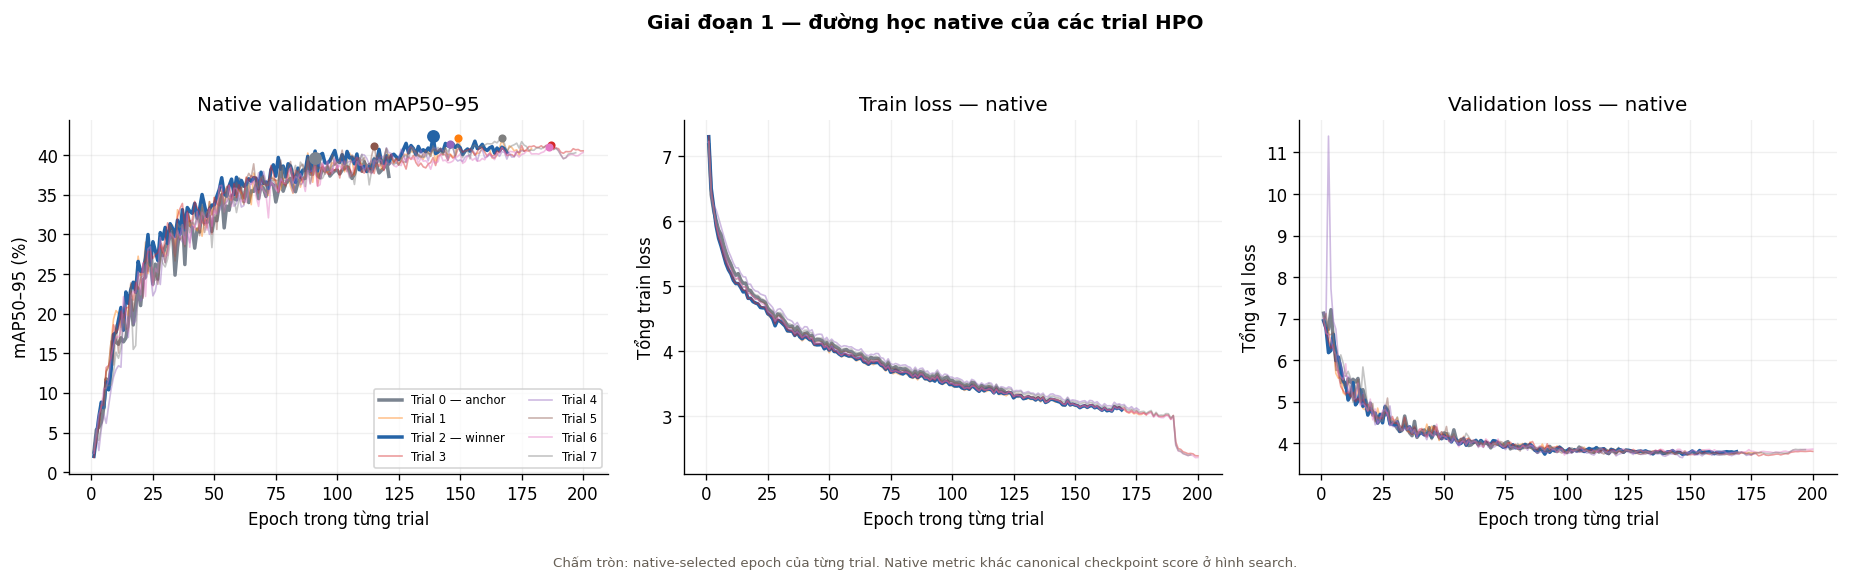

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8))
fig.suptitle("Giai đoạn 1 — đường học native của các trial HPO", fontweight="bold")
for trial in TRIALS_TO_PLOT:
    frame = hpo_epochs.loc[hpo_epochs["trial"] == trial]
    strong = trial in (0, WINNER_TRIAL)
    style = dict(color=trial_color(trial), lw=2.1 if strong else 1.0, alpha=1.0 if strong else 0.45)
    label = f"Trial {trial}" + (" — winner" if trial == WINNER_TRIAL else " — anchor" if trial == 0 else "")
    for ax, column, multiplier in zip(axes, ["map50_95", "train_loss", "val_loss"], [100, 1, 1]):
        ax.plot(frame["epoch"], multiplier * frame[column], label=label, **style)
        ax.set_xlabel("Epoch trong từng trial")
    best_epoch = int(trial_results[trial]["metrics"]["epoch"])
    best_value = float(frame.set_index("epoch").loc[best_epoch, "map50_95"]) * 100
    axes[0].scatter([best_epoch], [best_value], color=trial_color(trial), s=45 if strong else 15, zorder=4)
axes[0].set(title="Native validation mAP50–95", ylabel="mAP50–95 (%)")
axes[1].set(title="Train loss — native", ylabel="Tổng train loss")
axes[2].set(title="Validation loss — native", ylabel="Tổng val loss")
axes[0].legend(fontsize=7, ncol=2, loc="lower right")
finish_figure(fig, "02_hpo_all_trials", "Chấm tròn: native-selected epoch của từng trial. Native metric khác canonical checkpoint score ở hình search.")


## 6. HPO: xem chi tiết trial được chọn

Ba panel trên là loss box/cls/DFL lấy từ `native/results.csv` (thư viện đã áp loss gains).
Hai panel metric bên dưới vẫn là **native evaluator**, không gọi precision/recall đó là metric
tại confidence0,25 của bảng canonical. Panel LR vẽ actual LR của ba parameter groups;
`lr0` do TPE chọn vẫn giữ cố định trong trial, actual LR đổi theo warmup/scheduler.


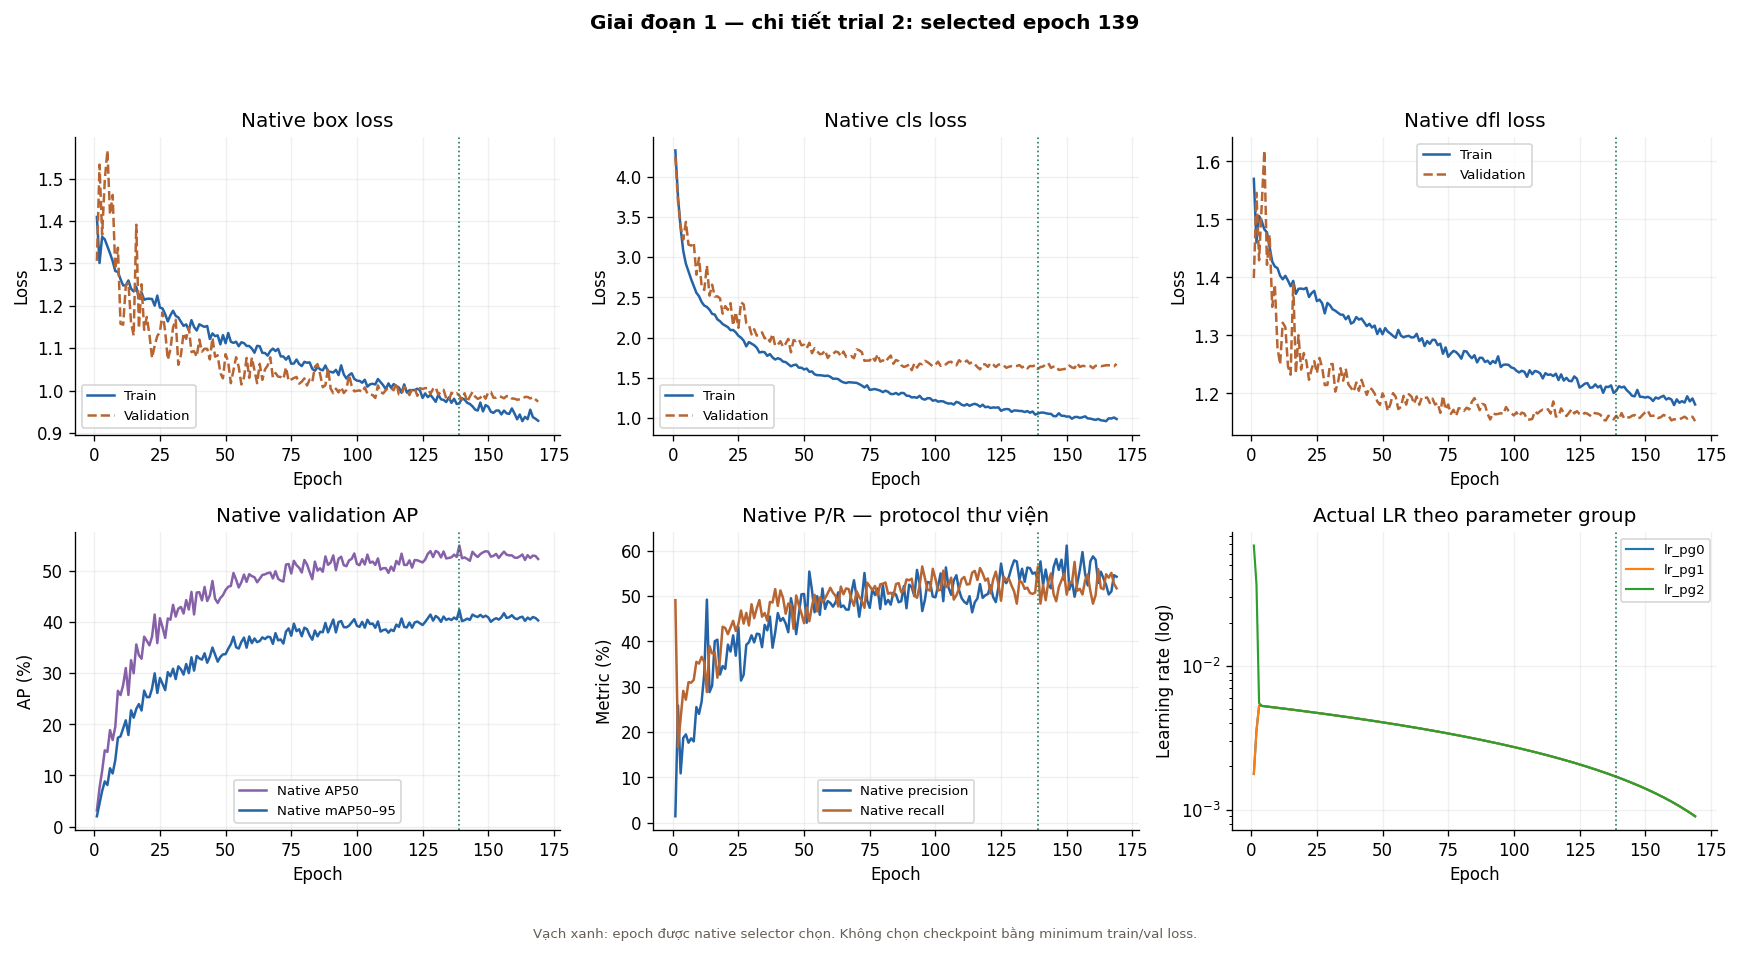

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14.5, 8.0))
fig.suptitle(f"Giai đoạn 1 — chi tiết trial {FOCUS_TRIAL}: selected epoch {FOCUS_BEST_EPOCH}", fontweight="bold")
component = component_frames.get(FOCUS_TRIAL)
for ax, loss_name in zip(axes[0], ["box", "cls", "dfl"]):
    if component is not None:
        ax.plot(component["epoch"], component[f"train/{loss_name}_loss"], color=COLORS["hpo"], label="Train")
        ax.plot(component["epoch"], component[f"val/{loss_name}_loss"], color=COLORS["tradeoff"], ls="--", label="Validation")
        ax.set(title=f"Native {loss_name} loss", xlabel="Epoch", ylabel="Loss")
        ax.legend(fontsize=8)
    else:
        ax.text(0.5, 0.5, "Không có native/results.csv\nKhông tự suy loss thành phần", ha="center", va="center", transform=ax.transAxes)
    ax.axvline(FOCUS_BEST_EPOCH, color=COLORS["dpo"], ls=":", lw=1)
axes[1, 0].plot(FOCUS["epoch"], FOCUS["map50"]*100, color=COLORS["purple"], label="Native AP50")
axes[1, 0].plot(FOCUS["epoch"], FOCUS["map50_95"]*100, color=COLORS["hpo"], label="Native mAP50–95")
axes[1, 0].set(title="Native validation AP", xlabel="Epoch", ylabel="AP (%)")
axes[1, 0].legend(fontsize=8)
axes[1, 1].plot(FOCUS["epoch"], FOCUS["precision"]*100, color=COLORS["hpo"], label="Native precision")
axes[1, 1].plot(FOCUS["epoch"], FOCUS["recall"]*100, color=COLORS["tradeoff"], label="Native recall")
axes[1, 1].set(title="Native P/R — protocol thư viện", xlabel="Epoch", ylabel="Metric (%)")
axes[1, 1].legend(fontsize=8)
for column in [name for name in FOCUS.columns if name.startswith("lr_pg")]:
    axes[1, 2].plot(FOCUS["epoch"], FOCUS[column], label=column, lw=1.3)
axes[1, 2].set_yscale("log")
axes[1, 2].set(title="Actual LR theo parameter group", xlabel="Epoch", ylabel="Learning rate (log)")
axes[1, 2].legend(fontsize=8)
for ax in axes[1]:
    ax.axvline(FOCUS_BEST_EPOCH, color=COLORS["dpo"], ls=":", lw=1)
finish_figure(fig, "03_hpo_focus_trial", "Vạch xanh: epoch được native selector chọn. Không chọn checkpoint bằng minimum train/val loss.")


## 7. KB2: native loss, DPO loss, weighted DPO và tổng loss

Log ghi train loss ở update1 rồi mỗi25 update, không có loss của mọi update.
`total_loss_reconstructed = native_loss + λ × dpo_loss` được **tính lại từ hai giá trị đã log**,
không giả là field total được ghi riêng. Native loss đã bao gồm background0,5.
Không so trực tiếp độ lớn loss này với loss HPO vì objective/batch/mask khác nhau.


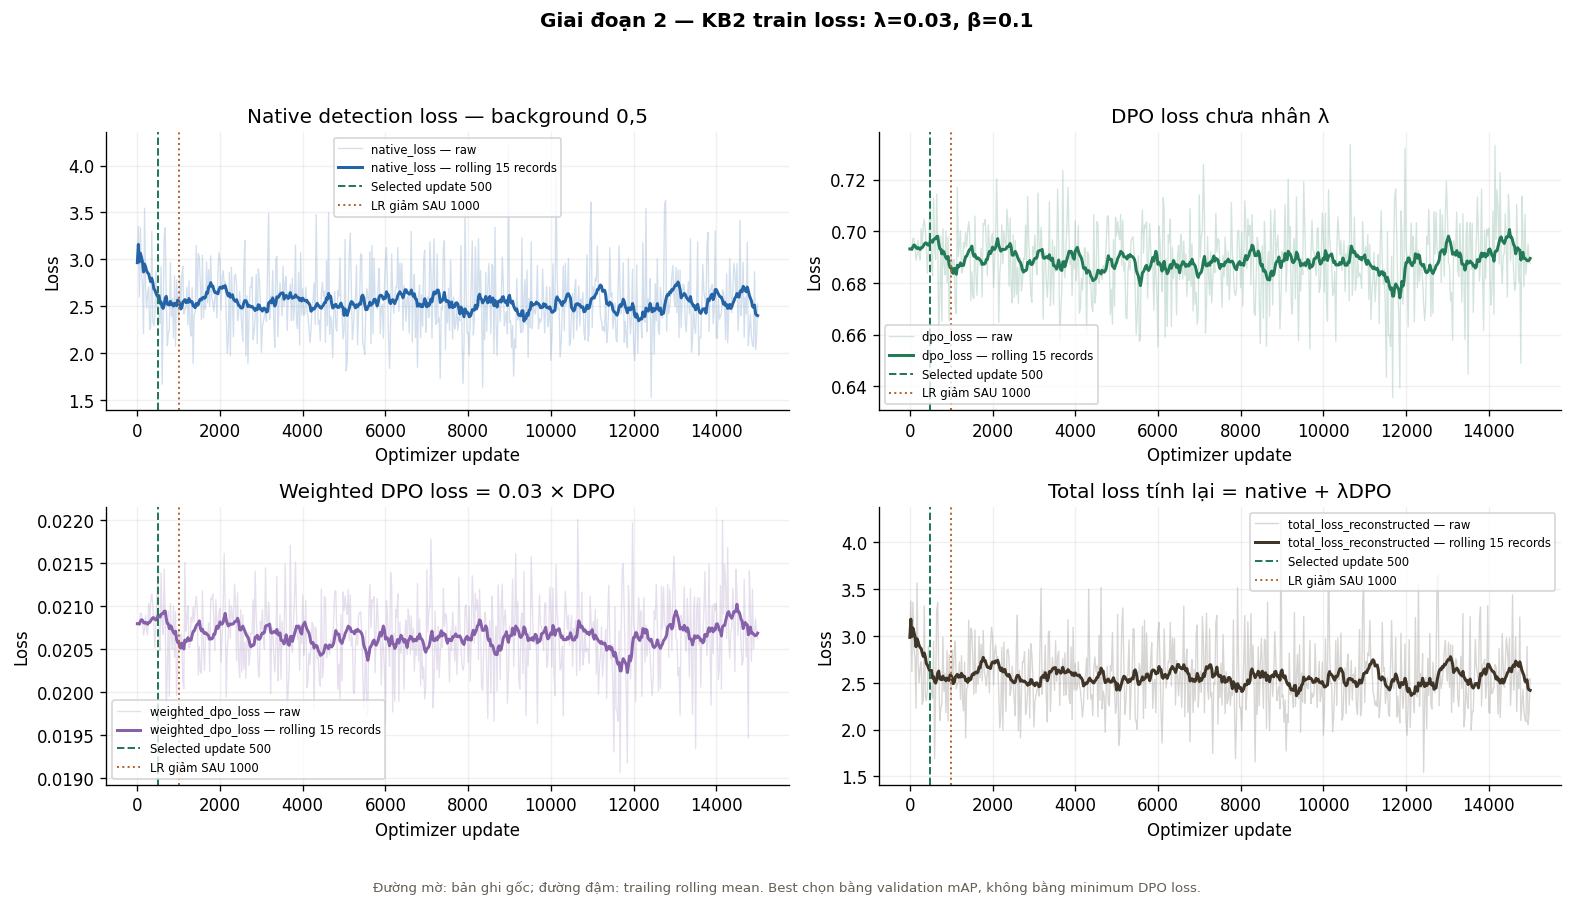

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13.2, 7.6))
fig.suptitle(f"Giai đoạn 2 — KB2 train loss: λ={DPO_WEIGHT}, β={BETA}", fontweight="bold")
panels = [
    ("native_loss", "Native detection loss — background 0,5", COLORS["hpo"]),
    ("dpo_loss", "DPO loss chưa nhân λ", COLORS["dpo"]),
    ("weighted_dpo_loss", f"Weighted DPO loss = {DPO_WEIGHT} × DPO", COLORS["purple"]),
    ("total_loss_reconstructed", "Total loss tính lại = native + λDPO", COLORS["ink"]),
]
for ax, (column, title, color) in zip(axes.flat, panels):
    loss_trace(ax, kb2_train, column, color, column)
    mark_kb2(ax)
    ax.set_title(title)
    ax.legend(fontsize=7)
finish_figure(fig, "04_kb2_training_losses", "Đường mờ: bản ghi gốc; đường đậm: trailing rolling mean. Best chọn bằng validation mAP, không bằng minimum DPO loss.")


## 8. KB2: canonical mAP theo update, toàn run và phóng to giai đoạn đầu

Mỗi marker là một lần evaluate thật trên479 ảnh validation. Đánh giá mỗi250 update tới2000,
sau đó mỗi1000. Step0 là TPE trước fine-tune. Best ở500 nằm **trước** khi LR giảm từ update1001.
Không kéo đường native HPO sang đây vì hai protocol khác nhau.


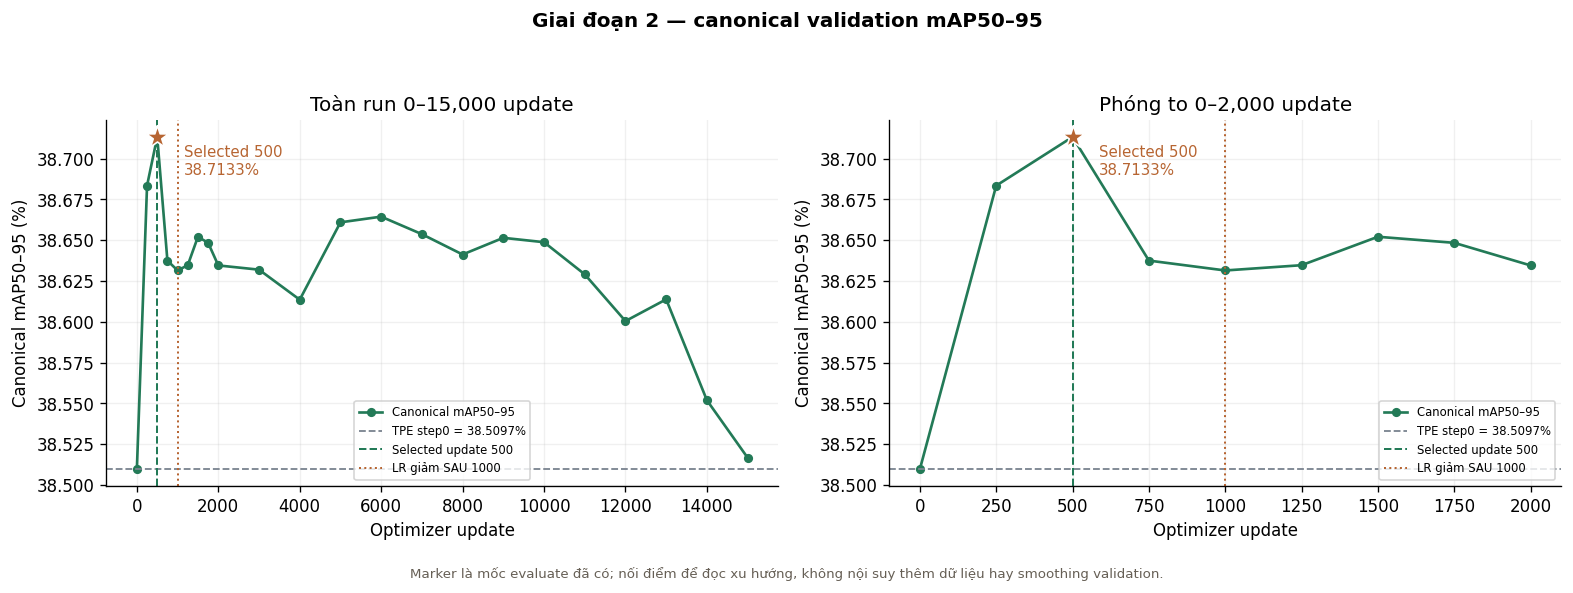

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.9))
fig.suptitle("Giai đoạn 2 — canonical validation mAP50–95", fontweight="bold")
baseline_ap = float(kb2_validation.iloc[0]["mAP50_95"]) * 100
selected_ap = float(selected_row["mAP50_95"]) * 100
early_limit = int(cfg["early_eval_until"])
for ax, frame, title in [
    (axes[0], kb2_validation, f"Toàn run 0–{BUDGET:,} update"),
    (axes[1], kb2_validation.loc[kb2_validation["step"] <= early_limit], f"Phóng to 0–{early_limit:,} update"),
]:
    ax.plot(frame["step"], frame["mAP50_95"]*100, "o-", ms=4.5, lw=1.6, color=COLORS["dpo"], label="Canonical mAP50–95")
    ax.axhline(baseline_ap, color=COLORS["anchor"], ls="--", lw=1.1, label=f"TPE step0 = {baseline_ap:.4f}%")
    ax.scatter([SELECTED_STEP], [selected_ap], marker="*", s=200, color=COLORS["tradeoff"], edgecolors="white", zorder=6)
    ax.annotate(f"Selected {SELECTED_STEP}\n{selected_ap:.4f}%", (SELECTED_STEP, selected_ap), xytext=(16, -5),
                textcoords="offset points", color=COLORS["tradeoff"], va="top", fontsize=9)
    mark_kb2(ax)
    ax.set(title=title, xlabel="Optimizer update", ylabel="Canonical mAP50–95 (%)")
axes[0].legend(fontsize=7, loc="lower center")
axes[1].legend(fontsize=7, loc="lower right")
finish_figure(fig, "05_kb2_validation_map", "Marker là mốc evaluate đã có; nối điểm để đọc xu hướng, không nội suy thêm dữ liệu hay smoothing validation.")


## 9. KB2: precision/recall/F1 và TP/FP/FN

Các operating metrics này dùng confidence0,25, matching class-aware IoU0,5.
Đó không phải `AR300` và không phải native P/R của HPO. FP giảm cùng TP giảm có thể khiến
precision tăng trong khi recall giảm; AP tốt nhất không nhất thiết là F1 tốt nhất.


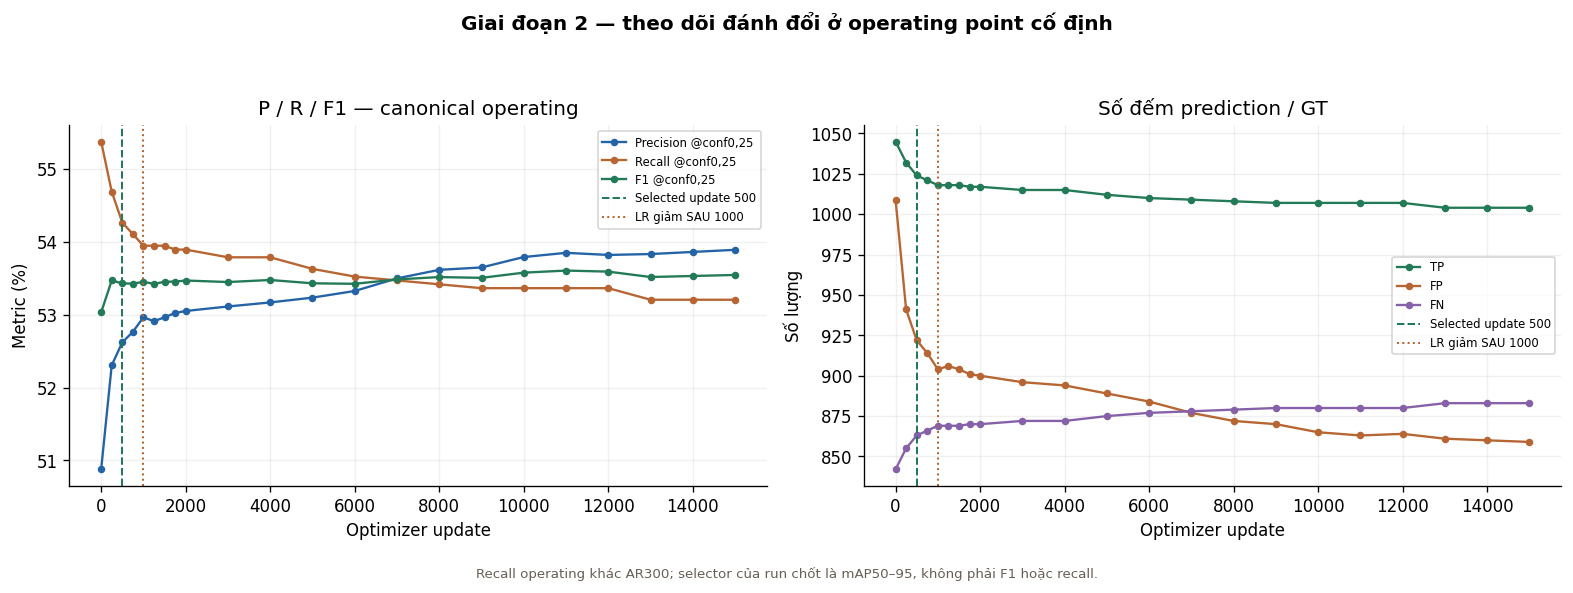

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.9))
fig.suptitle("Giai đoạn 2 — theo dõi đánh đổi ở operating point cố định", fontweight="bold")
for key, label, color in [
    ("precision", "Precision @conf0,25", COLORS["hpo"]),
    ("operating_recall", "Recall @conf0,25", COLORS["tradeoff"]),
    ("f1", "F1 @conf0,25", COLORS["dpo"]),
]:
    axes[0].plot(kb2_validation["step"], kb2_validation[key]*100, "o-", color=color, ms=3.5, lw=1.4, label=label)
for key, label, color in [("tp", "TP", COLORS["dpo"]), ("fp", "FP", COLORS["tradeoff"]), ("fn", "FN", COLORS["purple"])]:
    axes[1].plot(kb2_validation["step"], kb2_validation[key], "o-", color=color, ms=3.5, lw=1.4, label=label)
for ax in axes:
    mark_kb2(ax)
    ax.set_xlabel("Optimizer update")
    ax.legend(fontsize=7)
axes[0].set(title="P / R / F1 — canonical operating", ylabel="Metric (%)")
axes[1].set(title="Số đếm prediction / GT", ylabel="Số lượng")
finish_figure(fig, "06_kb2_operating_metrics", "Recall operating khác AR300; selector của run chốt là mAP50–95, không phải F1 hoặc recall.")


## 10. KB2: LR, gradient, preference margin và native foreground/background

Chỉ vẽ những diagnostic thực sự được log. Gradient norms là **trước clipping**;
weighted DPO norm đã nhân λ. Native cls foreground/background ở đây là các thành phần
classification đã có cls gain, **không phải toàn bộ native detection loss**.


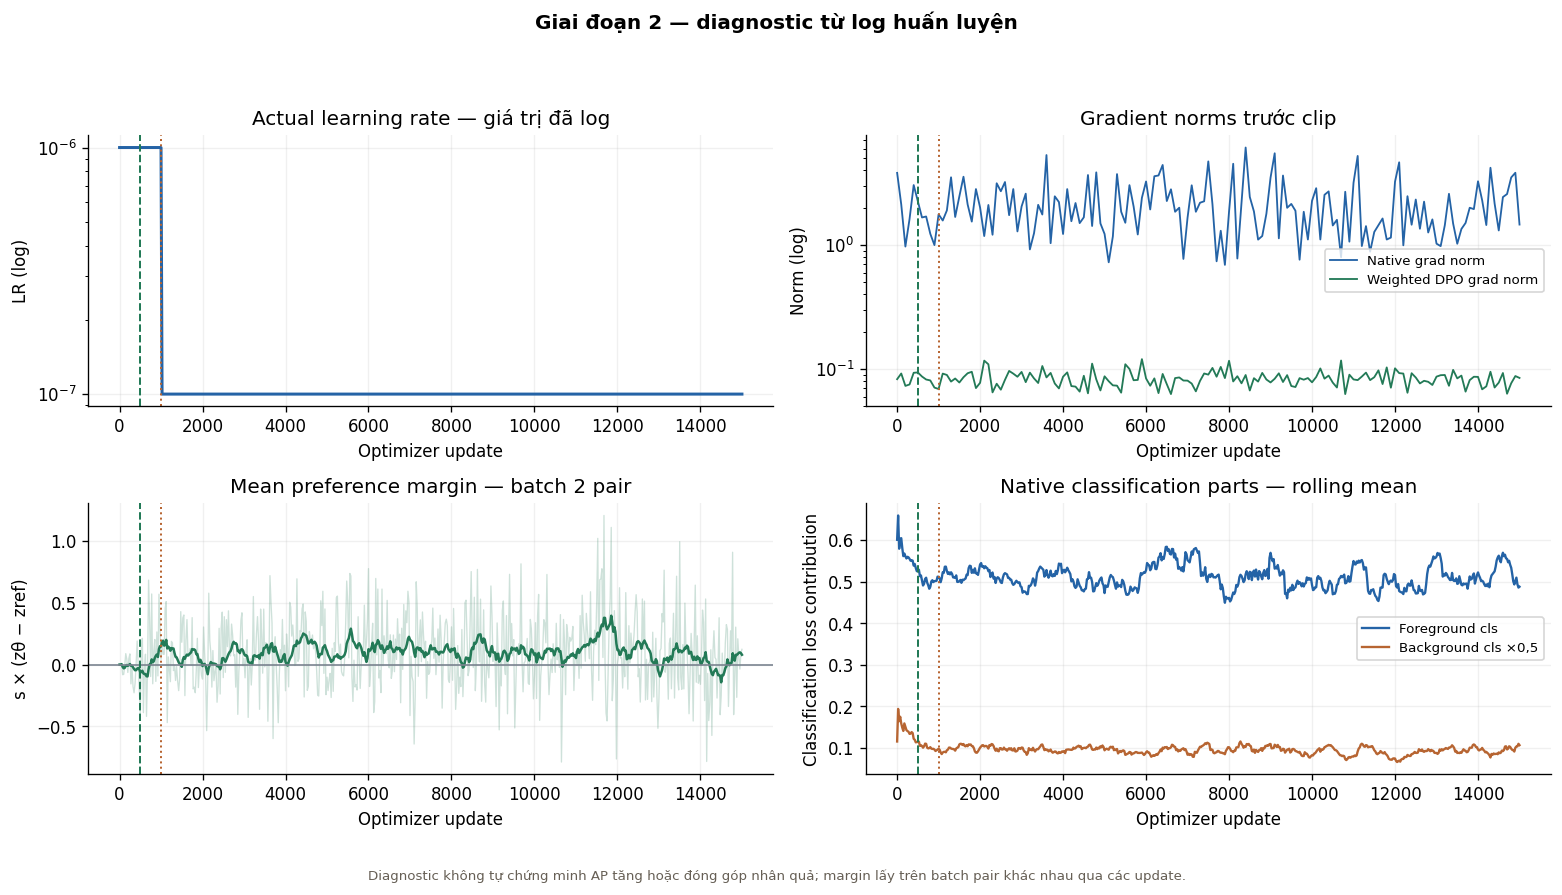

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13.2, 7.5))
fig.suptitle("Giai đoạn 2 — diagnostic từ log huấn luyện", fontweight="bold")
axes[0, 0].plot(kb2_train["step"], kb2_train["lr"], color=COLORS["hpo"], lw=1.8)
axes[0, 0].set_yscale("log")
axes[0, 0].set(title="Actual learning rate — giá trị đã log", ylabel="LR (log)")
gradient_columns = ["gradient.native_grad_norm", "gradient.weighted_dpo_grad_norm"]
if set(gradient_columns).issubset(kb2_train.columns):
    gradient_rows = kb2_train.dropna(subset=gradient_columns)
    for column, label, color in zip(gradient_columns, ["Native grad norm", "Weighted DPO grad norm"], [COLORS["hpo"], COLORS["dpo"]]):
        axes[0, 1].plot(gradient_rows["step"], gradient_rows[column], color=color, lw=1.1, label=label)
    axes[0, 1].set_yscale("log")
    axes[0, 1].set(title="Gradient norms trước clip", ylabel="Norm (log)")
    axes[0, 1].legend(fontsize=8)
else:
    axes[0, 1].text(0.5, 0.5, "Run không có gradient diagnostic", ha="center", transform=axes[0, 1].transAxes)
axes[1, 0].plot(kb2_train["step"], kb2_train["mean_margin"], color=COLORS["dpo"], alpha=0.22, lw=0.8)
axes[1, 0].plot(kb2_train["step"], kb2_train["mean_margin"].rolling(SMOOTH_WINDOW, min_periods=1).mean(), color=COLORS["dpo"], lw=1.5)
axes[1, 0].axhline(0, color=COLORS["anchor"], lw=1)
axes[1, 0].set(title="Mean preference margin — batch 2 pair", ylabel="s × (zθ − zref)")
for column, label, color in [
    ("native_partition.native_cls_foreground", "Foreground cls", COLORS["hpo"]),
    ("native_partition.native_cls_background_weighted", "Background cls ×0,5", COLORS["tradeoff"]),
]:
    if column in kb2_train.columns:
        axes[1, 1].plot(kb2_train["step"], kb2_train[column].rolling(SMOOTH_WINDOW, min_periods=1).mean(), label=label, color=color, lw=1.4)
axes[1, 1].set(title="Native classification parts — rolling mean", ylabel="Classification loss contribution")
axes[1, 1].legend(fontsize=8)
for ax in axes.flat:
    mark_kb2(ax, add_labels=False)
    ax.set_xlabel("Optimizer update")
finish_figure(fig, "07_kb2_diagnostics", "Diagnostic không tự chứng minh AP tăng hoặc đóng góp nhân quả; margin lấy trên batch pair khác nhau qua các update.")


## 11. Hình tổng quan hai giai đoạn để chèn báo cáo

Hai panel riêng, ghi đúng evaluator/trục. Không đọc độ cao của panel trái và phải như cùng
một đường metric. Điểm nối về mặt weights là **native-selected checkpoint** của winner TPE,
không phải weights ở epoch cuối169. KB2 khởi tạo từ checkpoint epoch139 đó.


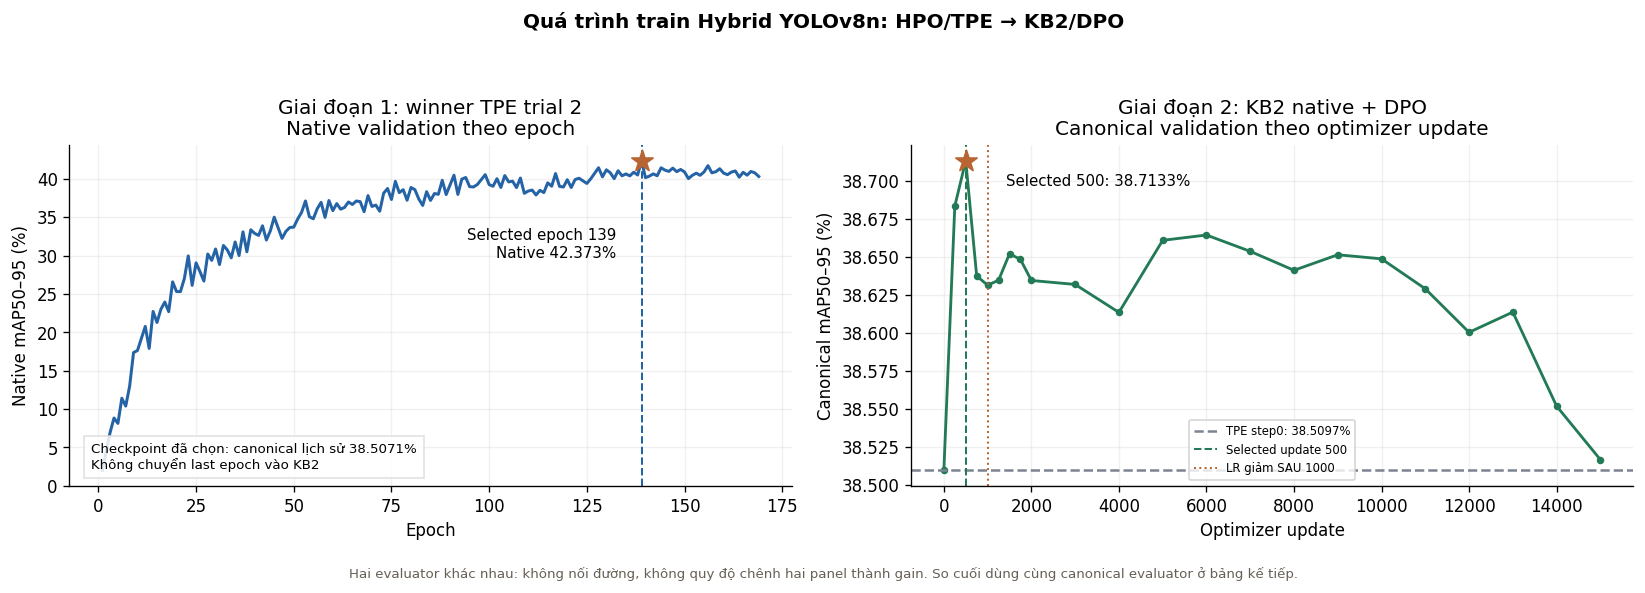

In [12]:
winner_history = hpo_epochs.loc[hpo_epochs["trial"] == WINNER_TRIAL].copy()
winner_native_best = float(winner_history.set_index("epoch").loc[WINNER_BEST_EPOCH, "map50_95"])*100
winner_canonical_history = float(hpo_trials.set_index("trial").loc[WINNER_TRIAL, "canonical_mAP50_95"])*100
fig, axes = plt.subplots(1, 2, figsize=(13.8, 4.9))
fig.suptitle("Quá trình train Hybrid YOLOv8n: HPO/TPE → KB2/DPO", fontweight="bold")
axes[0].plot(winner_history["epoch"], winner_history["map50_95"]*100, color=COLORS["hpo"], lw=1.8)
axes[0].axvline(WINNER_BEST_EPOCH, color=COLORS["hpo"], ls="--", lw=1.2)
axes[0].scatter([WINNER_BEST_EPOCH], [winner_native_best], marker="*", s=180, color=COLORS["tradeoff"], zorder=5)
axes[0].annotate(f"Selected epoch {WINNER_BEST_EPOCH}\nNative {winner_native_best:.3f}%", (WINNER_BEST_EPOCH, winner_native_best),
                 xytext=(-15, -58), textcoords="offset points", ha="right", fontsize=9)
axes[0].set(title=f"Giai đoạn 1: winner TPE trial {WINNER_TRIAL}\nNative validation theo epoch", xlabel="Epoch", ylabel="Native mAP50–95 (%)")
axes[0].text(0.03, 0.05, f"Checkpoint đã chọn: canonical lịch sử {winner_canonical_history:.4f}%\nKhông chuyển last epoch vào KB2", transform=axes[0].transAxes, fontsize=8,
             bbox=dict(facecolor="white", alpha=0.85, edgecolor="#DDDDDD"))
axes[1].plot(kb2_validation["step"], kb2_validation["mAP50_95"]*100, "o-", color=COLORS["dpo"], lw=1.7, ms=3.5)
axes[1].axhline(baseline_ap, ls="--", color=COLORS["anchor"], label=f"TPE step0: {baseline_ap:.4f}%")
axes[1].scatter([SELECTED_STEP], [selected_ap], marker="*", s=180, color=COLORS["tradeoff"], zorder=5)
axes[1].annotate(f"Selected {SELECTED_STEP}: {selected_ap:.4f}%", (SELECTED_STEP, selected_ap), xytext=(24, -8),
                 textcoords="offset points", fontsize=9, va="top")
mark_kb2(axes[1])
axes[1].set(title="Giai đoạn 2: KB2 native + DPO\nCanonical validation theo optimizer update", xlabel="Optimizer update", ylabel="Canonical mAP50–95 (%)")
axes[1].legend(fontsize=7, loc="lower center")
finish_figure(fig, "08_hybrid_two_stage_overview", "Hai evaluator khác nhau: không nối đường, không quy độ chênh hai panel thành gain. So cuối dùng cùng canonical evaluator ở bảng kế tiếp.")


## 12. Bảng cuối cùng, xuất dữ liệu và lưu nguồn

Đây là **ba checkpoint được chấm lại cùng canonical evaluator**: S0=trial0, TPE=trial2, Hybrid=best500.
Bảng không được dùng thay score lịch sử mà TPE đã quan sát, cũng không được chèn các điểm này vào
đường native từng epoch. Không có val loss KB2 trong log nên notebook không tự dựng một đường “val loss” KB2.


In [13]:
if FINAL_METRICS_CSV.is_file():
    INPUT_FILES.append(FINAL_METRICS_CSV)
    final_metrics_all = pd.read_csv(FINAL_METRICS_CSV, encoding="utf-8-sig")
    final_metrics = final_metrics_all.set_index("model").loc[["S0", "TPE", "selected"]].reset_index()
    show = final_metrics[["model", "mAP50_95", "mAP50", "mAP75", "precision", "operating_recall", "f1", "tp", "fp", "fn"]].copy()
    ratio_columns = ["mAP50_95", "mAP50", "mAP75", "precision", "operating_recall", "f1"]
    show[ratio_columns] = show[ratio_columns] * 100
    show["model"] = show["model"].map({"S0": "S0 — KB3 trial0", "TPE": "TPE — trial2", "selected": "Hybrid — best500"})
    print("Canonical checkpoint reload — tỷ lệ theo %, TP/FP/FN là số đếm:")
    display(show.round(4))
else:
    final_metrics = None
    print("Không có metrics.csv reload: bỏ qua bảng cuối, không tự thay bằng native metric.")

exports = {
    "kb3_trials_canonical_history.csv": hpo_trials,
    "kb3_epochs_native.csv": hpo_epochs,
    "kb2_train_logged.csv": kb2_train,
    "kb2_validation_canonical.csv": kb2_validation,
}
if final_metrics is not None:
    exports["checkpoints_canonical_reload.csv"] = final_metrics
for filename, frame in exports.items():
    frame.to_csv(OUTPUT_DIR / filename, index=False, encoding="utf-8-sig")

unique_inputs = sorted(set(INPUT_FILES))
provenance = {
    "purpose": "Plot existing Hybrid training logs; no model training/inference",
    "python": platform.python_version(),
    "versions": {"numpy": np.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__},
    "hpo_winner_trial": WINNER_TRIAL, "hpo_selected_epoch": WINNER_BEST_EPOCH,
    "hpo_actual_epochs_winner": int(trial_results[WINNER_TRIAL]["actual_epochs"]),
    "hpo_total_trial_epochs": int(hpo_trials["actual_epochs"].sum()),
    "kb2_selected_update": SELECTED_STEP, "kb2_budget": BUDGET,
    "kb2_train_log_records": len(kb2_train), "kb2_validation_records": len(kb2_validation),
    "kb2_selected_map_percent": float(selected_ap),
    "hpo_epoch_metric_protocol": "ultralytics_native_validation",
    "hpo_trial_objective": "canonical mAP50_95 of native-selected EMA checkpoint (historical)",
    "kb2_metric_protocol": "canonical ordinary YOLO validation; operating conf .25, IoU .5",
    "loss_smoothing_records": SMOOTH_WINDOW,
    "total_loss_reconstructed": "native_loss + dpo_weight*dpo_loss; not separately logged",
    "inputs_sha256": {str(path.relative_to(REPO_ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in unique_inputs},
    "figures": [str(path.relative_to(OUTPUT_DIR)) for path in FIGURE_FILES],
    "csv_files": list(exports),
}
(OUTPUT_DIR / "provenance.json").write_text(json.dumps(provenance, ensure_ascii=False, indent=2), encoding="utf-8")
readme = f"""# Biểu đồ quá trình train Hybrid HPO–DPO

Nguồn tạo: notebooks/plot_hybrid_training_20261113.ipynb — Run All.
Không train lại, không load weights, không inference.

- 01_hpo_search: objective canonical giữa các trial, không phải đường train liên tục.
- 02_hpo_all_trials: native mAP/train loss/val loss theo epoch của từng trial độc lập.
- 03_hpo_focus_trial: loss thành phần, native metrics và actual LR của trial {FOCUS_TRIAL}.
- 04_kb2_training_losses: native, DPO, weighted-DPO và total loss tính lại từ log.
- 05_kb2_validation_map: canonical mAP cả run và zoom 0–{early_limit} update.
- 06_kb2_operating_metrics: P/R/F1 và TP/FP/FN tại confidence0,25.
- 07_kb2_diagnostics: LR, gradient, preference margin, foreground/background cls.
- 08_hybrid_two_stage_overview: hai panel riêng, ghi đúng evaluator và trục.

HPO winner: trial {WINNER_TRIAL}, selected epoch {WINNER_BEST_EPOCH}.
KB2 selected: update {SELECTED_STEP}, mAP {selected_ap:.4f}% trong budget {BUDGET}.
HPO native metric KHÁC canonical KB2; không ghép hai đường để kết luận gain.
Metric mỗi checkpoint reload nằm trong checkpoints_canonical_reload.csv, nếu có.
Loss smoothing: trailing mean {SMOOTH_WINDOW} log records, không smoothing validation.
Không có KB2 validation loss trong log; không tự dựng dữ liệu đó.

Mỗi hình được xuất theo SAVE_FORMATS; có các CSV để vẽ lại.
provenance.json ghi config, protocol và SHA256 các log đầu vào.
"""
(OUTPUT_DIR / "README.md").write_text(readme, encoding="utf-8")
print(f"Đã xuất {len(FIGURE_FILES)} file hình và {len(exports)} CSV vào:\n{OUTPUT_DIR}")
print(f"Hình tổng quan: {OUTPUT_DIR / '08_hybrid_two_stage_overview.png'}")


Canonical checkpoint reload — tỷ lệ theo %, TP/FP/FN là số đếm:
           model  mAP50_95   mAP50   mAP75  precision  operating_recall      f1   tp   fp  fn
 S0 — KB3 trial0   36.0686 47.7023 41.2404    49.0785           49.3906 49.2340  932  967 955
    TPE — trial2   38.5097 50.4306 43.4945    50.8763           55.3789 53.0322 1045 1009 842
Hybrid — best500   38.7133 50.6287 43.7080    52.6208           54.2660 53.4307 1024  922 863
Đã xuất 24 file hình và 5 CSV vào:
/home/celine/Celine/graduate/RL-YOLO/docs/report_final/assets/hybrid_training_curves_20261113
Hình tổng quan: /home/celine/Celine/graduate/RL-YOLO/docs/report_final/assets/hybrid_training_curves_20261113/08_hybrid_two_stage_overview.png


## Cách dùng hình khi báo cáo

- Dùng `08_hybrid_two_stage_overview` để giới thiệu quá trình của hai giai đoạn.
- Dùng `01_hpo_search` + `03_hpo_focus_trial` để giải thích TPE chọn cấu hình và YOLO học bên trong trial.
- Dùng `04_kb2_training_losses` + `05_kb2_validation_map` để giải thích DPO loss khác selector mAP;
  train lâu hơn hay DPO loss giảm không bảo đảm checkpoint tốt hơn.
- Dùng `06_kb2_operating_metrics` để trình bày đánh đổi precision/recall thay vì chỉ nói “mọi metric tăng”.

Không suy thời điểm overfit chính xác chỉ từ một đường giảm; validation đã được dùng cho search/chọn model.
Chưa có xác nhận hybrid nhiều seed hoặc dữ liệu mới trong notebook này.
